# Chapter 3 — Bayesian Inference & Model Selection

## Introduction to Data Analysis and Machine Learning
### IFISC Master on Complex Systems

---

### What we cover

**Do all participants adapt with the same type of curve?**

| # | Section |
|---|---------|
| 0 | Setup: a small, ready-to-use real dataset |
| 1 | Understand the visuomotor experiment |
| 2 | Observe individual adaptation profiles |
| 3 | Fit the same three curves to every participant |
| 4 | Compare AIC/BIC and characterise the profiles |
| 5 | Test a specific hypothesis with LRT and BF |




---
# 0. Setup

We use **six participants**, keeping only the first day's adaptation block. Each row is one real trial. Each participant is fitted separately.

The subset was chosen after exploratory inspection to illustrate individual profiles. It is not a representative sample of the study.

**Extract the ZIP on your computer.** Keep the `Class4_Bayesian_Inference` folder and its contents together.

- **Local Jupyter:** open the notebook inside that folder and run it.
- **Colab:** upload that whole folder directly to **My Drive**, open its notebook in Colab, and run it. The next cell mounts Drive and selects the folder; it does nothing when running locally.

If you store the folder elsewhere in Drive, change only the folder path in the next cell.


In [1]:
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

    # Dynamically locate the directory containing 'class4_resources' in Google Drive
    base_path = "/content/drive/MyDrive"
    found = False

    # Fast search to avoid hanging in deep folder structures
    for root, dirs, files in os.walk(base_path):
        if "class4_resources" in dirs:
            os.chdir(root)
            print(f"Success! Working directory set to: {root}")
            found = True
            break

    if not found:
        print("[WARNING] Could not automatically locate 'class4_resources' folder.")
        print("Please make sure the project folder is uploaded to your Google Drive.")
else:
    print("Running locally. Working directory is the current directory.")

Running locally. Working directory is the current directory.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

plt.rcParams.update({"font.size": 12})


In [3]:
from pathlib import Path
from IPython.display import Image, display

resources = Path("class4_resources")
data = pd.read_csv(resources / "visuomotor_teaching_subset.csv")
subjects = data["subject"].unique().tolist()
print(f"{len(data)} observations from {len(subjects)} participants")
display(data.groupby("subject").size().reindex(subjects).to_frame("trials"))


1906 observations from 6 participants


,trials
subject,
sub-37,316
sub-11,317
sub-27,313
sub-10,320
sub-29,320
sub-19,320


`trial` starts at **0: the first trial after the rotation is introduced**. `error_deg` is the signed angular error between the cursor and the target.




---
# 1. The experiment

Participants used a **force sensor** to move a cursor from the centre of a screen towards a target. Targets could appear at eight positions around the centre.

Initially, force and cursor directions matched. The experiment then introduced a **45° rotation**. The same action now missed the target; participants could learn to change their force direction to compensate.

These are conceptual schematics, not recorded trajectories. The illustrated rotation direction is arbitrary.


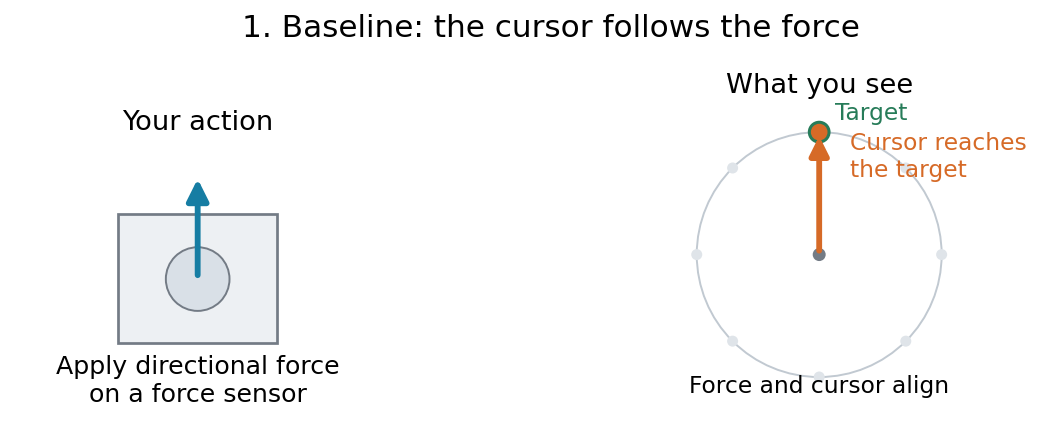

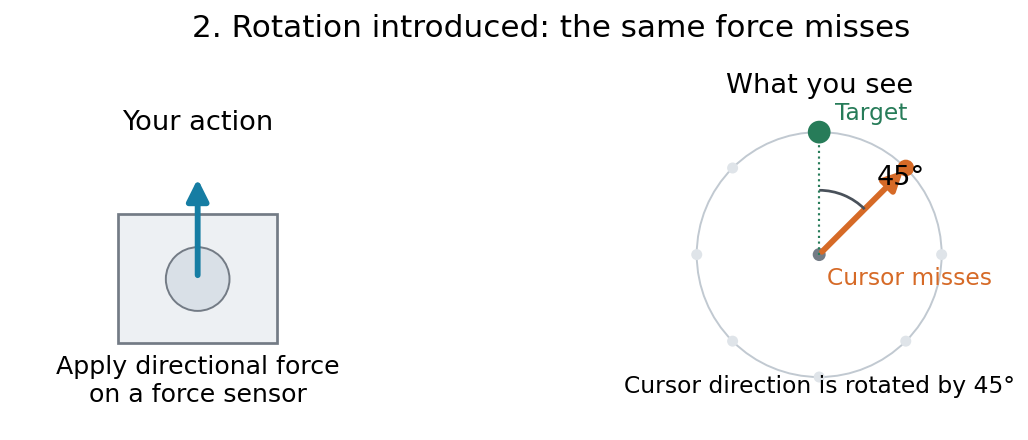

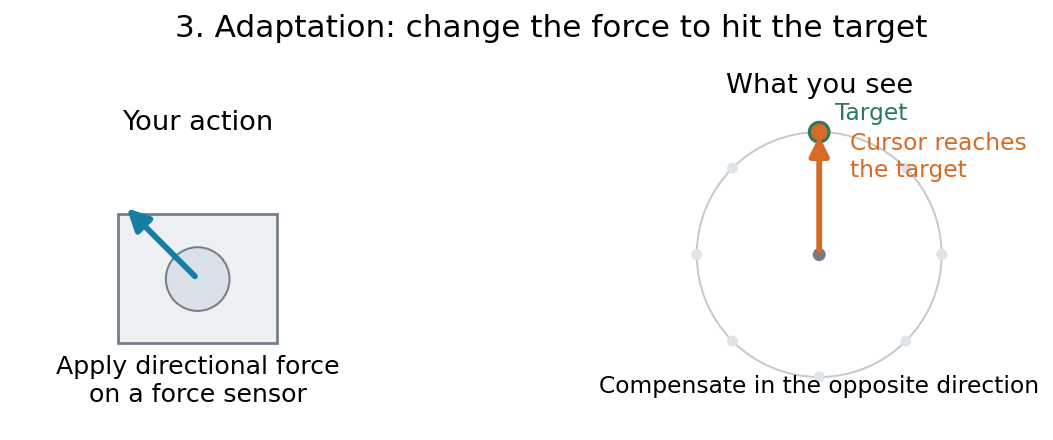

In [4]:
for step in [1, 2, 3]:
    diagram = resources / "assets" / f"experiment_step_{step}.png"
    display(Image(filename=str(diagram), width=800))


We analyse only the adaptation block shown below. Baseline and washout provide context; they are not fitted here.


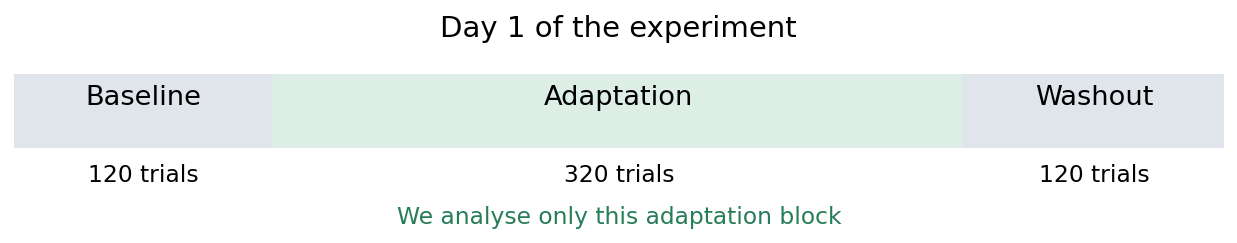

In [5]:
display(Image(filename=str(resources / "assets" / "experiment_timeline.png"), width=800))


---
# 2. Individual adaptation profiles

**Before choosing a model, look at the observations.**

Compare the change in angular error, its trial-to-trial variability and any persistent directional offset. All panels use the same axes; every observation is shown.


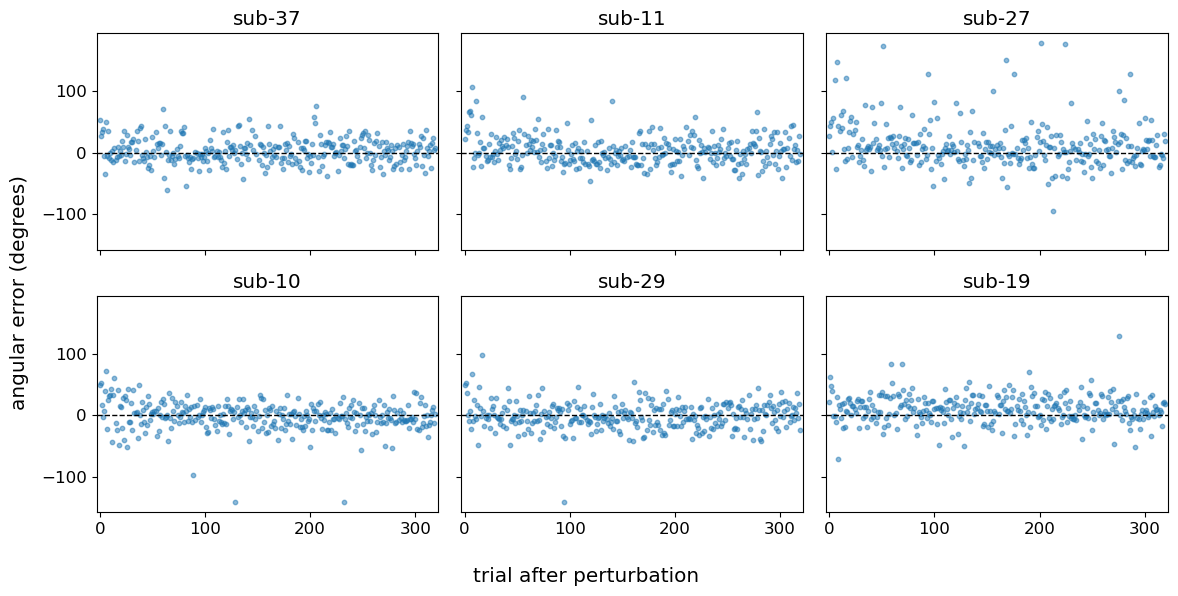

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for ax, subject in zip(axes.flat, subjects):
    observed = data[data["subject"] == subject]
    ax.scatter(observed["trial"], observed["error_deg"], s=10, alpha=0.5)
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_title(subject)
    ax.set_xlim(-3, 322)
fig.supxlabel("trial after perturbation")
fig.supylabel("angular error (degrees)")
plt.tight_layout()
plt.show()


---
# 3. Fit the same three curves

We compare three descriptions of the expected angular error:

**M0 — exponential to zero**

$$
f_0(t)=A e^{-t/\tau}
$$

**M1 — exponential with a free asymptote**

$$
f_1(t)=C+A e^{-t/\tau}
$$

**M2 — power law with a free asymptote**

$$
f_2(t)=C+A(1+t)^{-b}
$$

Here $A$ is a signed amplitude, $\tau$ is the exponential decay time in trials, $C$ is a signed asymptote in degrees, and $b$ controls the power-law decay.

For fitting and scoring, we assume independent Gaussian errors with a common variance within each participant:

$$
y_i=f(t_i)+\varepsilon_i,\qquad \varepsilon_i\sim N(0,\sigma^2)
$$

We estimate $\sigma$ from the residuals. This is a working likelihood; some participants have large errors and heavy tails. The comparisons remain conditional on this assumption.


In [7]:
def exp_zero(t, A, tau):
    return A * np.exp(-t / tau)

def exp_floor(t, A, tau, C):
    return C + A * np.exp(-t / tau)

def power_floor(t, A, b, C):
    return C + A * (1 + t)**(-b)

models = {
    "M0": {"function": exp_zero, "p0": [45, 5],
           "bounds": ([-np.inf, 1], [np.inf, 1000])},
    "M1": {"function": exp_floor, "p0": [45, 5, 0],
           "bounds": ([-np.inf, 1, -np.inf], [np.inf, 1000, np.inf])},
    "M2": {"function": power_floor, "p0": [45, 0.5, 0],
           "bounds": ([-np.inf, 0.01, -np.inf], [np.inf, 3, np.inf])},
}


## 3.1 Fit every participant

We reuse `curve_fit` from Chapter 2. The three models use the **same observations within each participant**. Try three starting decay values and retain the fit with the smallest residual sum of squares. This helps avoid poor local solutions. The fitted noise SD is the square root of the mean squared residual.


In [8]:
# Store detailed fit results in "fits" and comparison scores in "rows".
fits, rows = {}, []
# Fit each participant separately.
for subject in subjects:
    # Select this participant's observations.
    observed = data[data["subject"] == subject]
    t = observed["trial"].to_numpy(dtype=float)
    y = observed["error_deg"].to_numpy()
    fits[subject] = {}
    # Fit all candidate models to the same observations.
    for name, specification in models.items():
        function = specification["function"]
        candidates = []
        # Try three initial values for the second parameter:
        # b for the power law (M2), or tau for the exponentials (M0 and M1).
        # Multiple starting points help reduce the risk of poor local solutions.
        for start in ([0.1, 0.5, 1.] if name == "M2" else [5., 100., 500.]):
            # Copy the initial guesses so the model specification is unchanged.
            initial = specification["p0"].copy()
            initial[1] = start
            # Minimise the residual sum of squares within the parameter bounds.
            # The returned covariance matrix (_) is not used here.
            parameters, _ = curve_fit(
                function, t, y, p0=initial,
                bounds=specification["bounds"], maxfev=10000
            )
            candidates.append(parameters)
        # Retain the solution with the smallest residual sum of squares.
        # *p passes the parameter values as separate arguments to the function.
        parameters = min(
            candidates,
            key=lambda p: np.sum((y - function(t, *p))**2)
        )
        # Residuals are observed errors minus the fitted curve.
        residual = y - function(t, *parameters)
        # Estimate the Gaussian noise SD by maximum likelihood.
        # This uses denominator n, rather than a degrees-of-freedom correction.
        sigma = np.sqrt(np.mean(residual**2))
        # Under independent Gaussian errors, the joint log likelihood
        # is the sum of the individual residual log densities.
        loglik = stats.norm.logpdf(residual, loc=0, scale=sigma).sum()
        # Count every estimated parameter, including the noise SD.
        k = len(parameters) + 1
        # Keep the fitted parameters and diagnostics for later plots and tests.
        fits[subject][name] = {
            "parameters": parameters,
            "sigma": sigma,
            "residual": residual,
            "loglik": loglik,
            "k": k
        }
        # Calculate model-selection scores; lower values are preferred.
        # For BIC, n is this participant's number of observed trials.
        rows.append({
            "subject": subject,
            "model": name,
            "k": k,
            "AIC": -2*loglik + 2*k,
            "BIC": -2*loglik + k*np.log(len(y))
        })
# Collect all participant–model scores in one table.
scores = pd.DataFrame(rows)

## 3.2 See the fitted curves

First inspect the complete block. Then zoom into the first 60 trials and the angular-error range from -30 to 70 degrees to see where the curves differ. Observations outside this viewing window remain in the fit and in the full plot above. The zoom uses the same fitted parameters.


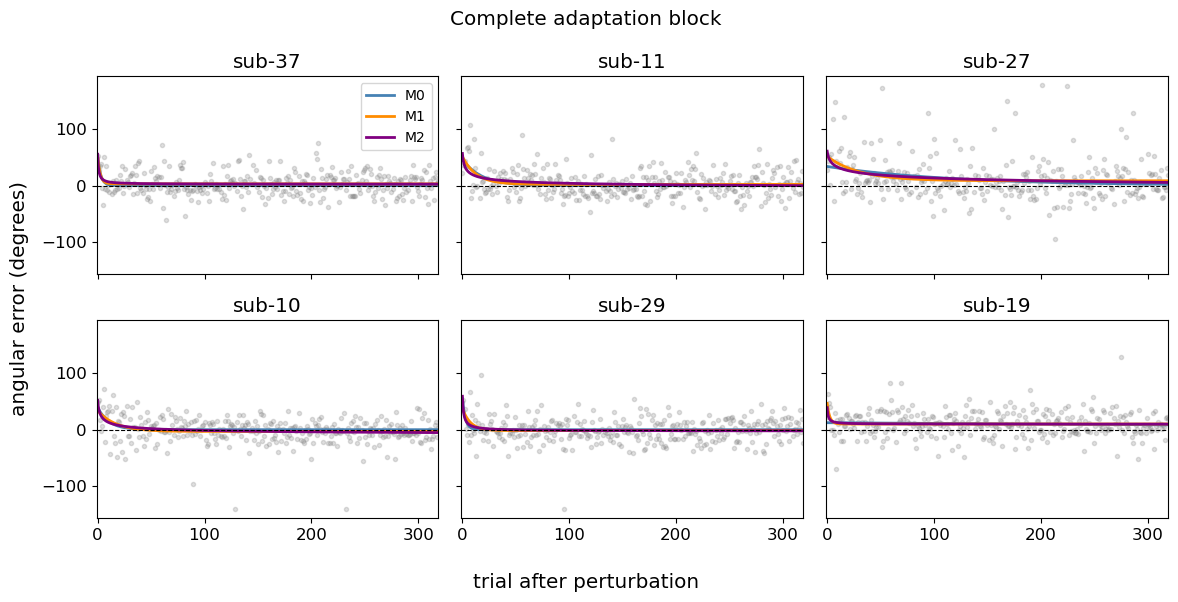

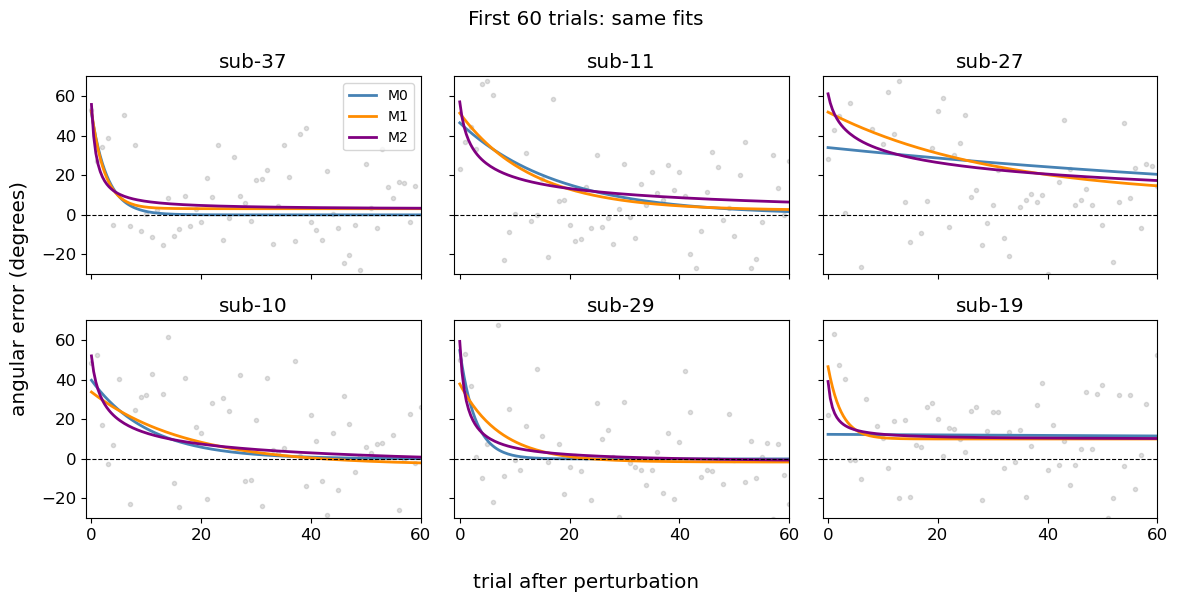

In [9]:
colours = {"M0": "steelblue", "M1": "darkorange", "M2": "purple"}
grid = np.linspace(0, 319, 800)

for end_trial, title in [(319, "Complete adaptation block"), (60, "First 60 trials: same fits")]:
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
    for ax, subject in zip(axes.flat, subjects):
        observed = data[data["subject"] == subject]
        ax.scatter(observed["trial"], observed["error_deg"], s=9, alpha=0.25, color="grey")
        for name in models:
            parameters = fits[subject][name]["parameters"]
            ax.plot(grid, models[name]["function"](grid, *parameters),
                    color=colours[name], lw=2, label=name)
        ax.axhline(0, color="black", ls="--", lw=0.8)
        ax.set(title=subject, xlim=(-1, end_trial))
        if end_trial == 60:
            ax.set_ylim(-30, 70)
    axes[0, 0].legend(fontsize=10)
    fig.suptitle(title)
    fig.supxlabel("trial after perturbation")
    fig.supylabel("angular error (degrees)")
    plt.tight_layout()
    plt.show()


---
# 4. Compare and characterise the profiles

## 4.1 AIC and BIC

Both criteria combine fit and parameter cost. **Lower scores are preferred.**

$$
\mathrm{AIC}=-2\ell_{\mathrm{MLE}}+2k
$$

$$
\mathrm{BIC}=-2\ell_{\mathrm{MLE}}+k\log n
$$

Here $n$ is the number of observed trials for that participant. Count every estimated parameter, including the noise SD: M0 has 3; M1 and M2 have 4.


In [10]:
score_table = scores.pivot(index="subject", columns="model", values=["AIC", "BIC"])
display(score_table.reindex(subjects).round(3))

for criterion in ["AIC", "BIC"]:
    scores["delta " + criterion] = scores[criterion] - scores.groupby("subject")[criterion].transform("min")


AIC                           BIC                    
model          M0        M1        M2        M0        M1        M2
subject                                                            
sub-37   2806.458  2801.218  2801.681  2817.725  2816.240  2816.704
sub-11   2866.027  2865.665  2871.989  2877.304  2880.700  2887.024
sub-27   3129.218  3125.471  3128.069  3140.457  3140.456  3143.054
sub-10   2913.537  2910.962  2908.924  2924.842  2926.035  2923.997
sub-29   2875.515  2876.410  2875.695  2886.820  2891.483  2890.768
sub-19   2892.915  2890.864  2893.072  2904.220  2905.937  2908.146

The next figure subtracts each participant's minimum score. A zero identifies that criterion's minimum; small differences mean little separation. Compare models **within a participant**, rather than comparing absolute scores between people.


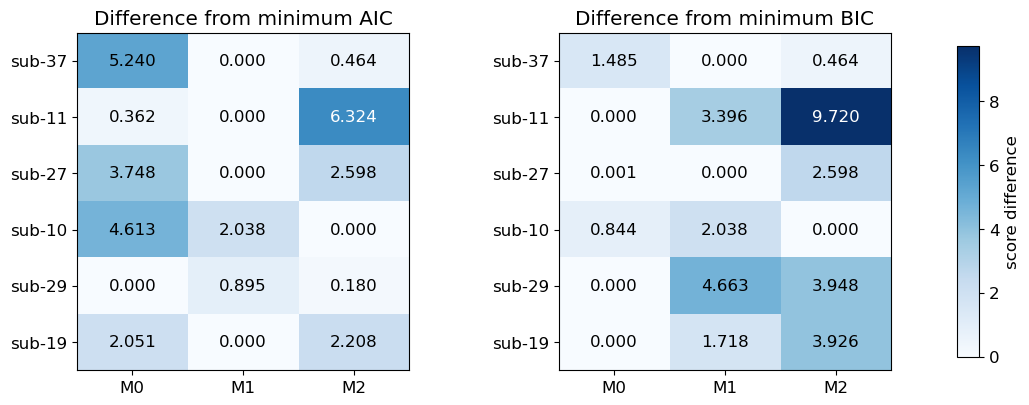

,AIC minimum,AIC gap to second,BIC minimum,BIC gap to second
subject,,,,
sub-37,M1,0.464,M1,0.464
sub-11,M1,0.362,M0,3.396
sub-27,M1,2.598,M1,0.001
sub-10,M2,2.038,M2,0.844
sub-29,M0,0.180,M0,3.948
sub-19,M1,2.051,M0,1.718


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
vmax = scores[["delta AIC", "delta BIC"]].to_numpy().max()
for ax, criterion in zip(axes, ["AIC", "BIC"]):
    delta = scores.pivot(index="subject", columns="model", values="delta " + criterion).reindex(subjects)
    im = ax.imshow(delta, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(3), delta.columns)
    ax.set_yticks(range(len(subjects)), subjects)
    ax.set_title("Difference from minimum " + criterion)
    for i in range(len(subjects)):
        for j in range(3):
            value = delta.iloc[i, j]
            ax.text(j, i, f"{value:.3f}", ha="center", va="center",
                    color="white" if value > vmax*0.55 else "black")
fig.subplots_adjust(left=0.09, right=0.83, bottom=0.13, top=0.88, wspace=0.45)
colourbar_axis = fig.add_axes([0.89, 0.16, 0.02, 0.69])
fig.colorbar(im, cax=colourbar_axis, label="score difference")
plt.show()

selection = []
for subject in subjects:
    row = {"subject": subject}
    for criterion in ["AIC", "BIC"]:
        ordered = scores[scores["subject"] == subject].sort_values(criterion)
        row[criterion + " minimum"] = ordered.iloc[0]["model"]
        row[criterion + " gap to second"] = ordered.iloc[1][criterion] - ordered.iloc[0][criterion]
    selection.append(row)
display(pd.DataFrame(selection).set_index("subject").round(3))


**Do all participants favour the same curve?** The minimum-score models vary in this subset, but many score gaps are small. These observations do not establish distinct types of learner. AIC and BIC can also prefer different models for the same participant.

## 4.2 Characterise subjects under one common model

Use M1 for everyone to compare its decay time and signed asymptote. A shorter decay time means a faster decrease of the fitted exponential component. The asymptote may include baseline bias; a nonzero value alone does not establish incomplete adaptation.

These are descriptive estimates under the same model. Model preference and parameter differences are different questions.


,decay time (trials),asymptote (degrees),noise SD (degrees)
subject,,,
sub-37,2.42,3.11,20.10
sub-11,13.16,2.17,21.94
sub-27,30.50,8.60,35.20
sub-10,17.20,-3.13,22.58
sub-29,7.50,-1.58,21.39
sub-19,2.43,10.08,21.88


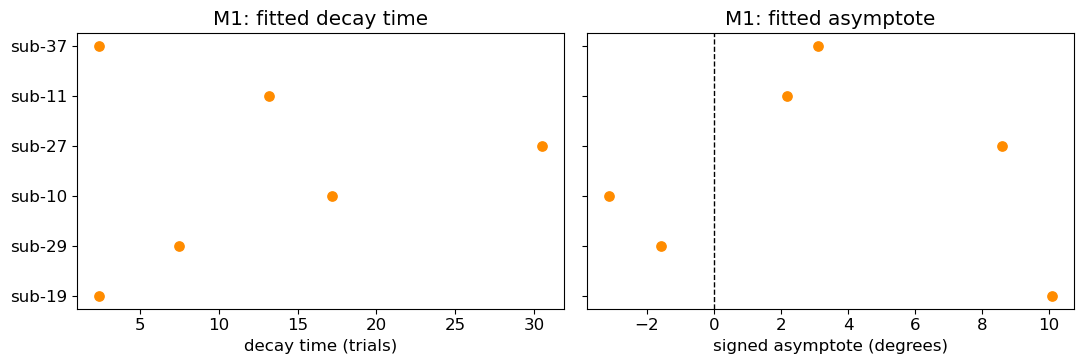

In [12]:
profiles = pd.DataFrame([
    {"subject": subject, "decay time (trials)": fits[subject]["M1"]["parameters"][1],
     "asymptote (degrees)": fits[subject]["M1"]["parameters"][2],
     "noise SD (degrees)": fits[subject]["M1"]["sigma"]}
    for subject in subjects
]).set_index("subject")
display(profiles.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
positions = np.arange(len(subjects))
axes[0].scatter(profiles["decay time (trials)"], positions, color="darkorange", s=45)
axes[0].set(xlabel="decay time (trials)", title="M1: fitted decay time")
axes[1].scatter(profiles["asymptote (degrees)"], positions, color="darkorange", s=45)
axes[1].axvline(0, color="black", ls="--", lw=1)
axes[1].set(xlabel="signed asymptote (degrees)", title="M1: fitted asymptote")
axes[0].set_yticks(positions, subjects)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()


---
# 5. One hypothesis: do we need a free asymptote?

We now focus on **sub-37**, chosen as the worked example. This asks a narrower question than comparing all three curve shapes: does M1 improve on M0 by allowing $C$ to vary?

$$
H_0:C=0,\qquad H_1:C\text{ is free}
$$

M0 is nested in M1. The LRT below compares these two exponentials; it does not compare the exponential with the power law.

## 5.1 Likelihood ratio test

Use the null/full convention from the slides:

$$
LR=\frac{L(M_0;\theta_{\mathrm{MLE},0})}{L(M_1;\theta_{\mathrm{MLE},1})}
$$

$$
D=-2\log LR=2(\ell_1-\ell_0)
$$

Freeing $C$ adds one parameter. The usual approximate null reference is $\chi^2_1$, provided the likelihood and regularity assumptions are suitable and fitted parameters are away from search limits.


In [13]:
subject = "sub-37"
observed = data[data["subject"] == subject]
t = observed["trial"].to_numpy(dtype=float)
y = observed["error_deg"].to_numpy()
loglik0 = fits[subject]["M0"]["loglik"]
loglik1 = fits[subject]["M1"]["loglik"]
LR = np.exp(loglik0 - loglik1)
D = -2*np.log(LR)
p_value = stats.chi2.sf(D, df=1)
print(f"LR = {LR:.4f}; D = {D:.3f}; approximate p-value = {p_value:.4f}")


LR = 0.0268; D = 7.240; approximate p-value = 0.0071


The small p-value is evidence against the zero-asymptote restriction under the assumed likelihood. It is not a probability that M0 is true.

## 5.2 Bayes factor

The BF averages the likelihood over each model's parameters using explicit priors:

$$
BF_{10}=\frac{p(y\mid M_1)}{p(y\mid M_0)}
$$

Use independent, proper priors: $A\sim N(0,60^2)$ and $C\sim N(0,20^2)$ in degrees; log-uniform priors for $\tau$ from 1 to 1000 trials and $\sigma$ from 1 to 90 degrees. M0 fixes $C=0$ and uses the same priors for its other parameters. These are illustrative choices.

The next cell imports the helper supplied in the ZIP. It integrates over all parameters to calculate model evidence; its implementation is outside this practical.


In [14]:
from class4_resources.bayes_helper import bayesian_comparison


In [15]:
bayes = bayesian_comparison(t, y, C_sd=20.)
print(f"BF10 = {bayes['BF10']:.3f}")

chosen_scores = score_table.loc[subject]
result = pd.DataFrame({
    "quantity": ["LRT: approximate p-value", "BF10", "AIC: M0 minus M1", "BIC: M0 minus M1"],
    "value": [p_value, bayes["BF10"],
              chosen_scores["AIC"]["M0"] - chosen_scores["AIC"]["M1"],
              chosen_scores["BIC"]["M0"] - chosen_scores["BIC"]["M1"]]})
display(result.round(4))


BF10 = 1.815


,quantity,value
0,LRT: approximate p-value,0.0071
1,BF10,1.8153
2,AIC: M0 minus M1,5.2403
3,BIC: M0 minus M1,1.4846


For this participant, the LRT rejects the zero-asymptote restriction at 0.05. AIC and BIC prefer M1 to M0, with different score gaps. The BF favours M1 only weakly under the stated priors.

The methods answer different questions. The LRT uses the best-fitting likelihoods; the BF averages over parameter values weighted by the priors. AIC and BIC balance fit against parameter cost. Their numbers are not interchangeable measures of evidence.

---
# Wrap-up

We observed individual profiles, fitted the same candidate curves, compared their scores, and characterised subjects under a common model. Different minimum-score curves do not by themselves establish different learning mechanisms, particularly when score gaps are small.

The final LRT and BF tested one explicit restriction within the exponential family. All conclusions remain conditional on the observation model and, for the BF, the priors.

## Data and references

- Dataset: Standage, Nashed, Flanagan and Gallivan, **Visuomotor Rotation Adaptation Experiment**, [OpenNeuro ds004021](https://openneuro.org/datasets/ds004021/versions/1.0.1), DOI: 10.18112/openneuro.ds004021.v1.0.1. Original data licence: CC0.
- Study: Areshenkoff et al. (2022), [Neural excursions from manifold structure explain patterns of learning during human sensorimotor adaptation](https://elifesciences.org/articles/74591), eLife.
- Subset: first-day adaptation trials from sub-37, sub-11, sub-27, sub-10, sub-29 and sub-19. Trial order is preserved; fourteen missing angular errors were omitted. Selection is illustrative and based on exploratory inspection.
- SciPy: [curve fitting](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) and [distributions](https://docs.scipy.org/doc/scipy/reference/stats.html).
